# Optimisation de la production : programmation linéaire et analyse de sensibilité

Une entreprise fabrique quatre produits (P1 à P4) à partir d'une seule matière première.
Objectif : trouver le plan de production qui maximise le bénéfice, puis utiliser la dualité et l'analyse
de sensibilité pour répondre à des questions de gestion. Résolution avec le solveur HiGHS.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, display

from src.modele import CONTRAINTES, PRODUITS, Donnees, resoudre, resoudre_dual
from src import analyses

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 110)

## 1. Le programme linéaire

max 4 x1 + 6 x2 + 7 x3 + 8 x4
s.c. x1 + x2 + x3 + x4 = 950 ; x4 ≥ 400 ; 2 x1 + 3 x2 + 4 x3 + 7 x4 ≤ 4 600 (matière) ; 3 x1 + 4 x2 + 5 x3 + 6 x4 ≤ 5 000 (heures)

In [2]:
r = resoudre()
print(f"Bénéfice optimal : {r.profit:,.0f} €".replace(",", " "))
pd.DataFrame({"quantité": r.x, "coût réduit": r.couts_reduits,
              "bénéfice unitaire min": [p[0] for p in r.plages_couts],
              "bénéfice unitaire max": [p[1] for p in r.plages_couts]}, index=PRODUITS)

Bénéfice optimal : 6 650 €


,quantité,coût réduit,bénéfice unitaire min,bénéfice unitaire max
P1,0.00,-1.00,-inf,5.00
P2,400.00,0.00,5.50,6.67
P3,150.00,0.00,6.50,8.00
P4,400.00,0.00,-inf,10.00


In [3]:
pd.DataFrame({"marge": r.ecarts, "prix dual": r.prix_duaux,
              "plage basse": [p[0] for p in r.plages_seconds_membres],
              "plage haute": [p[1] for p in r.plages_seconds_membres]}, index=CONTRAINTES)

,marge,prix dual,plage basse,plage haute
Ventes totales,0.00,3.00,850.00,"1,000.00"
Demande min. P4,0.00,-2.00,275.00,437.50
Matière première,0.00,1.00,"4,450.00","4,850.00"
Heures de travail,250.00,0.00,"4,675.00","4,750.00"


## 2. Le programme dual

min 950 y1 + 400 y2 + 4 600 y3 + 5 000 y4, avec y1 libre (contrainte d'égalité) et y2 ≤ 0 (contrainte « ≥ »).

In [4]:
z, y = resoudre_dual()
print(f"Valeur du dual : {z:,.0f} € (identique au primal : dualité forte)".replace(",", " "))
pd.Series(y, index=["y1 (ventes)", "y2 (demande P4)", "y3 (matière)", "y4 (heures)"], name="valeur")

Valeur du dual : 6 650 € (identique au primal : dualité forte)


y1 (ventes)        3.00
y2 (demande P4)   -2.00
y3 (matière)       1.00
y4 (heures)        0.00
Name: valeur, dtype: float64

## 3. Prix de vente et volume de ventes

Prédiction par l'analyse de sensibilité, puis vérification par une nouvelle résolution.

In [5]:
analyses.scenarios_prix_et_ventes()

,scenario,profit,x1,x2,x3,x4,prediction_sensibilite
0,Solution initiale,"6,650.00",0.00,400.00,150.00,400.00,–
1,"P2 : prix +0,50 €","6,850.00",0.00,400.00,150.00,400.00,"P2 dans la base, hausse dans la plage : +0,50 × 400 = +200 €"
2,"P1 : prix +0,60 €","6,650.00",0.00,400.00,150.00,400.00,"P1 hors base, coût réduit 1 € > 0,60 € : rien ne change"
3,"P3 : prix −0,60 €","6,575.00",0.00,512.50,0.00,437.50,"6,40 € < borne basse 6.50 € : la base change, nouvelle résolution nécessaire"
4,Ventes : 980 au lieu de 950,"6,740.00",0.00,520.00,60.00,400.00,prix dual 3 € × 30 = +90 €


## 4. Matière première : baisse, achat et valeur marginale

In [6]:
analyses.scenarios_matiere()

,scenario,profit,x1,x2,x3,x4,prediction_sensibilite
0,Matière : 4 500 (−100),"6,550.00",0.00,500.00,50.00,400.00,4 500 dans [4450 ; 4850] : −100 × 1 € = −100 €
1,Matière : 4 400 (−200),"6,400.00",50.00,500.00,0.00,400.00,"4 400 < 4450 : hors plage, la perte dépasse 200 €"
2,Matière : 4850 (achat de 250 unités),"6,900.00",0.00,150.00,400.00,400.00,jusqu'à 250 unités valorisées 1 € chacune
3,Matière : 4900 (au-delà),"6,900.00",0.00,150.00,400.00,400.00,au-delà de la plage : plus aucun gain


### Analyse paramétrique (contrainte sur P4 supprimée)

In [7]:
para = analyses.parametrique_matiere()
analyses.paliers(para)

,matiere_debut,matiere_fin,valeur_marginale,profit_fin
0,"1,900.00","2,850.00",2.00,"5,700.00"
1,"2,860.00","3,800.00",1.00,"6,650.00"
2,"3,810.00","4,550.00",0.33,"6,900.00"
3,"4,560.00","6,000.00",0.00,"6,900.00"


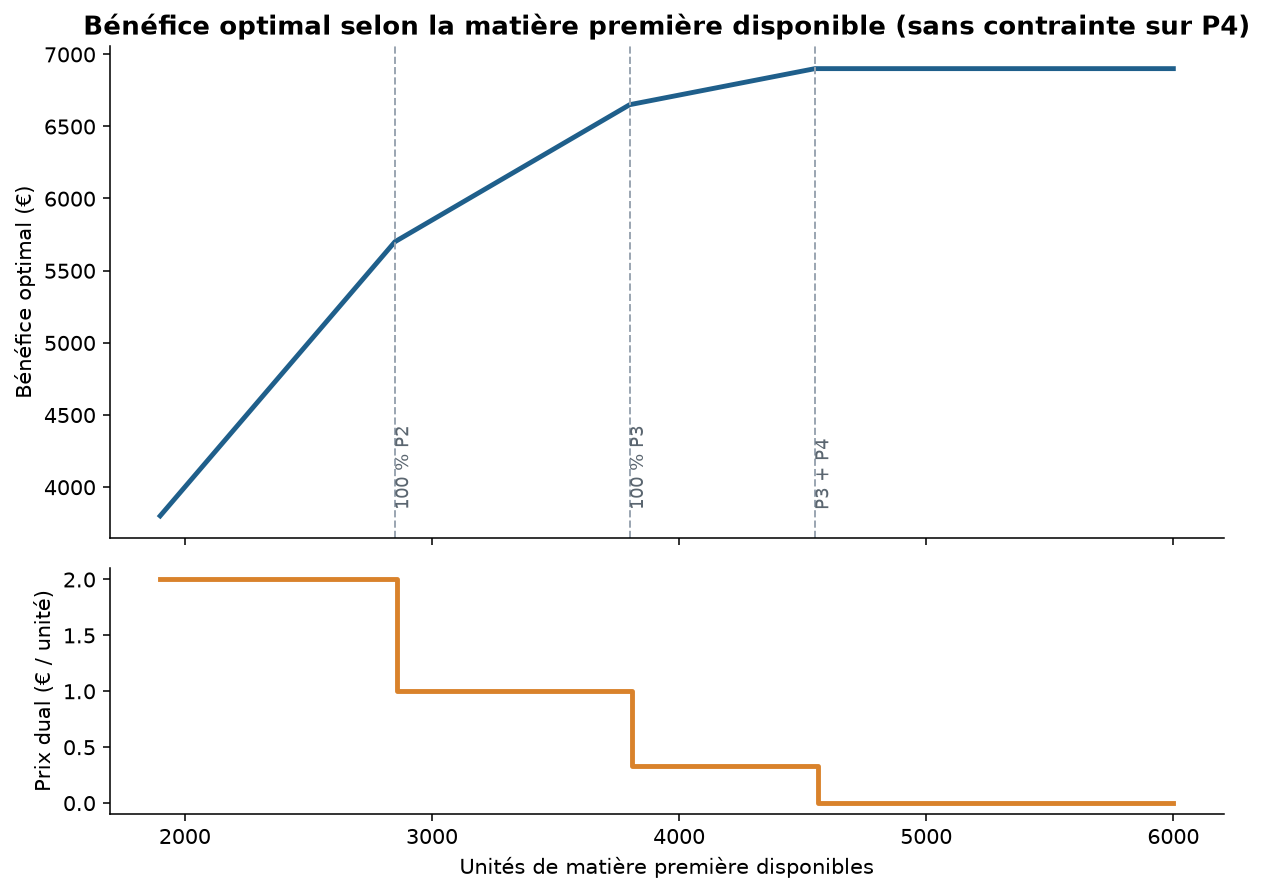

In [8]:
display(Image("../outputs/figures/parametrique_matiere.png"))

## 5. Intérim

In [9]:
res = analyses.heures_interim()
print(f"Heures utilisées : {res['heures_utilisees']:.0f} / 5000 | prix dual des heures : {res['prix_dual_heures']:.0f} €")
print(res["conclusion"])

Heures utilisées : 4750 / 5000 | prix dual des heures : 0 €
Les heures ne sont pas saturées (prix dual nul) : des heures en plus ne permettent pas de produire davantage, car la matière première est le facteur limitant. L'intérim n'a d'intérêt que si son coût horaire, honoraires compris, est inférieur au coût interne (6 €/h) pour remplacer des heures existantes.


## 6. Investissement

+100 ventes et +500 unités de matière par mois ; gains actualisés à 10 %.

In [10]:
print(f"Bénéfice avec l'investissement : {resoudre(replace(Donnees(), ventes=1050, matiere=5100)).profit:,.0f} € par mois".replace(",", " "))
t = analyses.investissement()
print(f"Délai de récupération d'un investissement de 30 000 € : {analyses.delai_recuperation(t, 30_000):.2f} ans")
t

Bénéfice avec l'investissement : 7 100 € par mois
Délai de récupération d'un investissement de 30 000 € : 7.39 ans


,annee,gain_actualise,gain_cumule
0,0,"5,400.00","5,400.00"
1,1,"4,909.09","10,309.09"
2,2,"4,462.81","14,771.90"
3,3,"4,057.10","18,829.00"
4,4,"3,688.27","22,517.27"
5,5,"3,352.98","25,870.25"
6,6,"3,048.16","28,918.41"
7,7,"2,771.05","31,689.46"


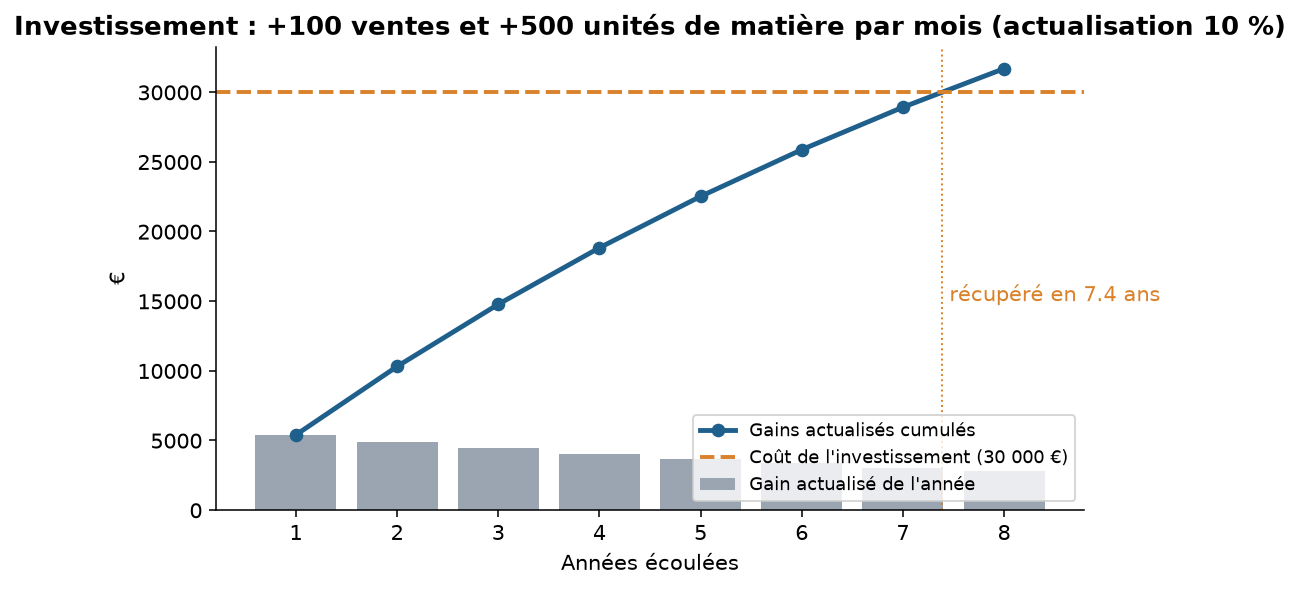

In [11]:
display(Image("../outputs/figures/investissement.png"))

## Conclusion

- La matière première est la seule ressource limitante : chaque unité supplémentaire vaut 1 €, dans la limite de 250 unités.
- Les heures de travail ne sont pas saturées : l'intérim n'a d'intérêt que pour réduire les coûts, pas pour produire plus.
- L'analyse de sensibilité prédit correctement l'effet des petites modifications ; hors des plages de validité, il faut résoudre de nouveau le modèle.